# Machine Learning – Assignment 2
## Multi-class Classification of Mobile Phone Price Range

**Student ID:** 2026CT05120  |**Student Name:** MOHD NAZIM ANSARI  |  **Programme:** M.Tech (AIML / DSE), WILP  |  **Course:** Machine Learning

**Dataset:** Kaggle – *Mobile Price Classification* (`train.csv`, 2,000 labelled phones, 20 features)
**Target:** `price_range` – 0 = low cost, 1 = medium cost, 2 = high cost, 3 = very high cost
**Models:** Logistic Regression · Decision Tree · k-Nearest Neighbours · Gaussian Naive Bayes · Random Forest
**Metrics:** Accuracy · AUC · Precision · Recall · F1 · MCC (all multi-class, macro-averaged)

**Contents**

| Assignment step | Sections in this notebook |
|---|---|
| Step 1 – Dataset choice | 2 |
| Step 2 – Data preprocessing | 3 |
| Step 3 – Models and evaluation metrics | 4 – 5 |
| Step 4 / 5 / 6 – Repository files, requirements, README | 6 – 8 |
| Step 7 – Virtual Lab screenshot | 9 |

## 1. Problem Statement

A mobile-phone seller wants to place a new phone in the correct **price band** using only its technical specification (battery, RAM, camera, screen, connectivity, …). This notebook treats the task as a **four-class supervised classification problem** and compares five prescribed algorithms on the same data, the same stratified 80:20 split and the same six evaluation metrics, then names the best model for this dataset and explains why.

## 0. Environment setup
All settings that may need changing are in the first code cell: the seed, the split size and where the data is searched for. Run the notebook from inside the `model/` folder (or from the project root); the project folder is detected automatically.

In [1]:
import json
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_curve, confusion_matrix, classification_report)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier

try:
    from IPython.display import display, HTML
except ImportError:                                   # plain-Python fallback
    display = print
    HTML = str

warnings.filterwarnings("ignore", category=FutureWarning)

# ----------------------------- configuration -----------------------------
STUDENT_ID = "2026CT05120"
RANDOM_STATE = 42           # one fixed seed for the split, the models and the cross-validation
TEST_SIZE = 0.20               # 80:20 train-test split
CV_FOLDS = 5                   # folds for the small hyper-parameter searches (training data only)

TRAIN_CSV_PATH = None          # optional: set an explicit path, e.g. r"C:\data\train.csv"
TEST_CSV_PATH = None           # optional: the unlabeled Kaggle test.csv (used only for the bonus predictions)

# project root: one level up when this notebook runs from a folder called "model"
PROJECT_DIR = Path("..") if Path.cwd().name.lower() == "model" else Path(".")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "model"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = PROJECT_DIR / "figures"
for folder in (DATA_DIR, MODEL_DIR, OUTPUT_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("Project folder:", PROJECT_DIR.resolve())

Python 3.14.0 | scikit-learn 1.9.0 | pandas 3.0.5 | numpy 2.5.3
Project folder: C:\Bits Mtech Data\Machine Learning\TEST\project-folder


## 2. Step 1 – Dataset choice

### 2.1 Load the data
The notebook looks for `train*.csv` (and `test*.csv`) in the current folder, `data/`, and the project folder, so the Kaggle file names can be used as they are. Only **`train.csv`** is labelled; the Kaggle `test.csv` has no `price_range` column, so no metric can be computed on it. The 80:20 evaluation split is therefore made from `train.csv`.

In [2]:
SEARCH_DIRS = []
for folder in (Path("."), Path("data"), PROJECT_DIR, DATA_DIR, Path("..") / "data"):
    if folder not in SEARCH_DIRS and folder.is_dir():
        SEARCH_DIRS.append(folder)


def locate_csv(prefix, required_column, exclude=("test_data.csv",)):
    # first CSV called <prefix>*.csv that contains the required column
    for folder in SEARCH_DIRS:
        for path in sorted(folder.glob(prefix + "*.csv")):
            if path.name in exclude:
                continue
            try:
                if required_column in pd.read_csv(path, nrows=0).columns:
                    return path
            except Exception:
                continue
    return None


train_path = Path(TRAIN_CSV_PATH) if TRAIN_CSV_PATH else locate_csv("train", "price_range")
if train_path is None or not train_path.exists():
    raise FileNotFoundError(
        "train.csv was not found.\n"
        )

df_raw = pd.read_csv(train_path)
print("Training file :", train_path)
print("Shape (rows, columns):", df_raw.shape)
display(df_raw.head())

Training file : ..\data\train.csv
Shape (rows, columns): (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


### 2.2 Why this dataset?
- **Meets the size rules:** 2,000 instances (minimum 1,000) and 20 predictor variables (minimum 12).
- **Genuine multi-class problem:** four ordered price bands, which allows macro-averaged metrics, one-vs-rest AUC and a look at *how far off* the wrong predictions are.
- **Realistic, interpretable features:** battery capacity, RAM, camera megapixels, screen size, connectivity flags – every feature can be explained to a non-technical reader.
- **Mixed feature types:** 14 numeric specifications and 6 binary (yes/no) flags, so scaling is needed for some models and not for others.
- **Hidden data-quality problems:** the file has no `NaN` cells, but a few columns contain physically impossible zeros (Section 3.1), so missing-value handling is still a real decision.



### 2.3 Target variable and feature types

In [3]:
TARGET = "price_range"
CLASS_LABELS = {0: "0 - Low", 1: "1 - Medium", 2: "2 - High", 3: "3 - Very high"}

feature_cols = [c for c in df_raw.columns if c != TARGET]
binary_cols = [c for c in feature_cols if set(df_raw[c].dropna().unique()) <= {0, 1}]
numeric_cols = [c for c in feature_cols if c not in binary_cols]

FEATURE_INFO = {
    "battery_power": ("numeric", "Battery capacity (mAh)"),
    "blue": ("binary", "Has Bluetooth (1 = yes)"),
    "clock_speed": ("numeric", "Processor clock speed (GHz)"),
    "dual_sim": ("binary", "Supports dual SIM (1 = yes)"),
    "fc": ("numeric", "Front camera (megapixels)"),
    "four_g": ("binary", "Has 4G (1 = yes)"),
    "int_memory": ("numeric", "Internal memory (GB)"),
    "m_dep": ("numeric", "Mobile depth / thickness (cm)"),
    "mobile_wt": ("numeric", "Weight of the phone (g)"),
    "n_cores": ("numeric", "Number of processor cores"),
    "pc": ("numeric", "Primary (rear) camera (megapixels)"),
    "px_height": ("numeric", "Screen resolution height (pixels)"),
    "px_width": ("numeric", "Screen resolution width (pixels)"),
    "ram": ("numeric", "Random-access memory (MB)"),
    "sc_h": ("numeric", "Screen height (cm)"),
    "sc_w": ("numeric", "Screen width (cm)"),
    "talk_time": ("numeric", "Longest talk time on one charge (hours)"),
    "three_g": ("binary", "Has 3G (1 = yes)"),
    "touch_screen": ("binary", "Has touch screen (1 = yes)"),
    "wifi": ("binary", "Has Wi-Fi (1 = yes)"),
}

feature_table = pd.DataFrame({
    "Feature": feature_cols,
    "Type": [FEATURE_INFO.get(c, ("numeric", ""))[0] for c in feature_cols],
    "Meaning": [FEATURE_INFO.get(c, ("", ""))[1] for c in feature_cols],
    "Distinct values": [df_raw[c].nunique() for c in feature_cols],
    "Min": [df_raw[c].min() for c in feature_cols],
    "Max": [df_raw[c].max() for c in feature_cols],
})
display(feature_table)

print(f"Target variable      : {TARGET}  ->  {CLASS_LABELS}")
print(f"Number of predictors : {len(feature_cols)}  ({len(numeric_cols)} numeric, {len(binary_cols)} binary)")
print(f"Binary flags         : {binary_cols}")
print("Categorical (text) predictors: none  -> every column is already numeric")

,Feature,Type,Meaning,Distinct values,Min,Max
0,battery_power,numeric,Battery capacity (mAh),1094,501.0,1998.0
1,blue,binary,Has Bluetooth (1 = yes),2,0.0,1.0
2,clock_speed,numeric,Processor clock speed (GHz),26,0.5,3.0
3,dual_sim,binary,Supports dual SIM (1 = yes),2,0.0,1.0
4,fc,numeric,Front camera (megapixels),20,0.0,19.0
5,four_g,binary,Has 4G (1 = yes),2,0.0,1.0
6,int_memory,numeric,Internal memory (GB),63,2.0,64.0
7,m_dep,numeric,Mobile depth / thickness (cm),10,0.1,1.0
8,mobile_wt,numeric,Weight of the phone (g),121,80.0,200.0
9,n_cores,numeric,Number of processor cores,8,1.0,8.0


Target variable      : price_range  ->  {0: '0 - Low', 1: '1 - Medium', 2: '2 - High', 3: '3 - Very high'}
Number of predictors : 20  (14 numeric, 6 binary)
Binary flags         : ['blue', 'dual_sim', 'four_g', 'three_g', 'touch_screen', 'wifi']
Categorical (text) predictors: none  -> every column is already numeric


### 2.4 Class distribution (class imbalance check)

,Class,Count,Percentage
0,0 - Low,500,25.0
1,1 - Medium,500,25.0
2,2 - High,500,25.0
3,3 - Very high,500,25.0


Imbalance ratio (largest : smallest class) = 1.00 : 1
Accuracy of a model that always predicts one class = 25.00%


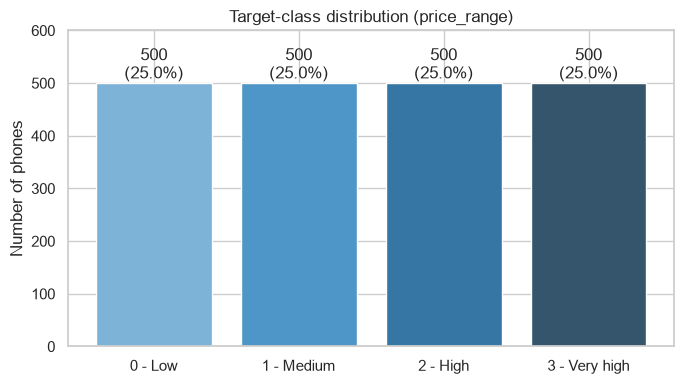

In [4]:
class_counts = df_raw[TARGET].value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": [CLASS_LABELS[c] for c in class_counts.index],
    "Count": class_counts.values,
    "Percentage": (class_counts / class_counts.sum() * 100).round(2).values,
})
display(class_distribution)

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Imbalance ratio (largest : smallest class) = {imbalance_ratio:.2f} : 1")
print(f"Accuracy of a model that always predicts one class = {class_counts.max() / class_counts.sum():.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(class_distribution["Class"], class_distribution["Count"], color=sns.color_palette("Blues_d", 4))
for bar, pct in zip(bars, class_distribution["Percentage"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{int(bar.get_height())}\n({pct}%)",
            ha="center", va="bottom")
ax.set_title("Target-class distribution (price_range)")
ax.set_ylabel("Number of phones")
ax.set_ylim(0, class_counts.max() * 1.2)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

**Class-balance conclusion.** The four price bands are (almost) perfectly balanced, so the dataset has **no class-imbalance problem**: no resampling or class weighting is needed, a stratified split is enough to keep the proportions, and Accuracy is a trustworthy metric here. Macro-averaged Precision, Recall and F1 are still reported (each class counts equally), together with AUC and MCC, because the assignment prescribes all six metrics.

### 2.5 Which features matter? (exploratory analysis)

Absolute correlation with price_range (top 6):


,|correlation|
ram,0.917
battery_power,0.201
px_width,0.166
px_height,0.149
int_memory,0.044
sc_w,0.039


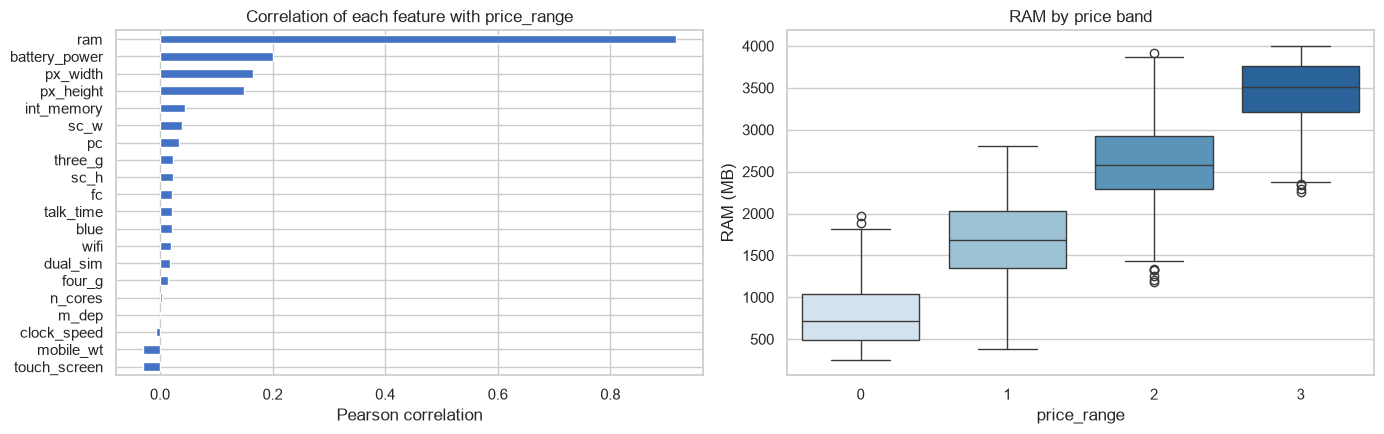

In [5]:
corr_with_target = df_raw.corr()[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False)
print("Absolute correlation with price_range (top 6):")
display(corr_with_target.abs().head(6).round(3).to_frame("|correlation|"))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
corr_with_target.sort_values().plot(kind="barh", ax=axes[0], color="#4472C4")
axes[0].set_title("Correlation of each feature with price_range")
axes[0].set_xlabel("Pearson correlation")
sns.boxplot(data=df_raw, x=TARGET, y="ram", ax=axes[1], palette="Blues")
axes[1].set_title("RAM by price band")
axes[1].set_xlabel("price_range")
axes[1].set_ylabel("RAM (MB)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "eda_correlation_and_ram.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Step 2 – Data preprocessing

All steps are fitted **only on the training data**: every learned operation (median imputation, standardisation) sits inside a scikit-learn `Pipeline`, so the held-out test rows are never seen while fitting.

### 3.1 Missing values: identify and handle
Two checks are made: (1) `NaN` cells, and (2) **hidden missing values** – zeros in columns where zero is physically impossible. A zero is *valid* for `fc` and `pc` (a phone may have no front or rear camera) and for the binary flags, but a screen width of 0 cm or a screen height of 0 pixels cannot occur.

In [6]:
nan_counts = df_raw.isna().sum()
print("Cells containing NaN (explicit missing values):", int(nan_counts.sum()))

zero_counts = (df_raw[numeric_cols] == 0).sum()
zero_counts = zero_counts[zero_counts > 0]
ZERO_MEANING = {
    "fc": "valid - phone without a front camera",
    "pc": "valid - phone without a rear camera",
    "px_height": "IMPOSSIBLE - a screen cannot have 0 pixels of height",
    "sc_w": "IMPOSSIBLE - a screen cannot be 0 cm wide",
}
zero_report = pd.DataFrame({
    "Column": zero_counts.index,
    "Zero values": zero_counts.values,
    "% of rows": (zero_counts.values / len(df_raw) * 100).round(2),
    "Interpretation": [ZERO_MEANING.get(c, "check manually") for c in zero_counts.index],
})
display(zero_report)

Cells containing NaN (explicit missing values): 0


,Column,Zero values,% of rows,Interpretation
0,fc,474,23.70,valid - phone without a front camera
1,pc,101,5.05,valid - phone without a rear camera
2,px_height,2,0.10,IMPOSSIBLE - a screen cannot have 0 pixels of ...
3,sc_w,180,9.00,IMPOSSIBLE - a screen cannot be 0 cm wide


### Missing-value handling decision
- The file has **no `NaN` cells**, so the explicit-missing check is clean.
- The columns whose zeros are impossible (`px_height`, `sc_w`) are treated as **hidden missing values**: every `0` is replaced by the **median of the non-zero training values** of that column. This is done by `SimpleImputer(missing_values=0, strategy="median")` inside the pipeline, so the median is learned from the training rows only and the rule is also applied automatically to any new data.
- `fc` and `pc` keep their zeros because they carry real information (no camera).
- A second `SimpleImputer(strategy="median")` stays in every pipeline as a safety net for any genuine `NaN` in future data.

Set `ZERO_AS_MISSING_COLS = []` in the next cell to switch the zero rule off and compare.

In [7]:
ZERO_AS_MISSING_COLS = [c for c in ["px_height", "sc_w"] if c in feature_cols]

# column order produced by the first pipeline step: the zero-fixed columns first, then all remaining columns
PIPELINE_FEATURES = ZERO_AS_MISSING_COLS + [c for c in feature_cols if c not in ZERO_AS_MISSING_COLS]

before = (df_raw[ZERO_AS_MISSING_COLS] == 0).sum()
print("Zeros that will be treated as missing and imputed with the training median:")
display(before.rename("rows affected").to_frame())

Zeros that will be treated as missing and imputed with the training median:


,rows affected
px_height,2
sc_w,180


### 3.2 Duplicates: identify and handle

In [8]:
duplicate_count = int(df_raw.duplicated().sum())
print("Duplicate rows (all 21 columns identical):", duplicate_count)

df = df_raw.drop_duplicates().reset_index(drop=True)
print("Rows before:", len(df_raw), "| rows after removing duplicates:", len(df), "| removed:", len(df_raw) - len(df))

Duplicate rows (all 21 columns identical): 0
Rows before: 2000 | rows after removing duplicates: 2000 | removed: 0


Duplicates are removed **before** the split, so an identical phone can never appear in both the training and the test set. (If the count above is 0, nothing is removed.)

### 3.3 Categorical encoding
**Not required for the predictors.** There are no text/nominal columns: the six binary flags are already coded 0/1 (the correct representation for a yes/no feature) and the remaining 14 columns are numeric. One-hot encoding would only duplicate the binary flags. The target `price_range` is already an integer label 0–3, which every scikit-learn classifier accepts. The next cell verifies this.

In [9]:
text_columns = [c for c in df.columns if df[c].dtype == "object"]
non_01 = [c for c in binary_cols if not set(df[c].unique()) <= {0, 1}]
print("Text / object columns needing encoding :", text_columns if text_columns else "none")
print("Binary flags that are not strictly 0/1 :", non_01 if non_01 else "none")
print("Target classes (integer coded)         :", sorted(df[TARGET].unique().tolist()))

Text / object columns needing encoding : none
Binary flags that are not strictly 0/1 : none
Target classes (integer coded)         : [0, 1, 2, 3]


### 3.4 Feature scaling: where is it required?
| Model | Scaling | Reason |
|---|---|---|
| Logistic Regression | **StandardScaler** | gradient-based optimisation and the regularisation penalty depend on feature scale (RAM is in the thousands, `clock_speed` below 3) |
| k-Nearest Neighbours | **StandardScaler** | distances would be dominated by large-valued features such as `ram` and `px_width` |
| Decision Tree | none | splits compare one feature at a time, so the result does not change under monotonic rescaling |
| Random Forest | none | same reason as the Decision Tree |
| Gaussian Naive Bayes | none | it fits a separate mean and variance for every feature and class, so rescaling does not change its decisions |

### 3.5 Train–test split (80:20, stratified, fixed seed)
`stratify=y` keeps the four price bands in the same proportion in both parts, and `random_state` makes the split reproducible. The held-out 20% is saved untouched as `test_data.csv`.

In [10]:
X = df[feature_cols].copy()
y = df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print(f"Training set: {X_train.shape}  ({len(X_train) / len(X):.0%})")
print(f"Test set    : {X_test.shape}  ({len(X_test) / len(X):.0%})")

stratification_check = pd.DataFrame({
    "Full data %": y.value_counts(normalize=True).sort_index() * 100,
    "Training %": y_train.value_counts(normalize=True).sort_index() * 100,
    "Test %": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
stratification_check.index = [CLASS_LABELS[i] for i in stratification_check.index]
display(stratification_check)

# the held-out test set, exactly as it is in the original file (no preprocessing applied)
test_data = X_test.copy()
test_data[TARGET] = y_test.values
test_data_path = PROJECT_DIR / "test_data.csv"
test_data.to_csv(test_data_path, index=False)
print(f"\nSaved the held-out test set ({len(test_data)} rows) -> {test_data_path}")

Training set: (1600, 20)  (80%)
Test set    : (400, 20)  (20%)


,Full data %,Training %,Test %
0 - Low,25.0,25.0,25.0
1 - Medium,25.0,25.0,25.0
2 - High,25.0,25.0,25.0
3 - Very high,25.0,25.0,25.0



Saved the held-out test set (400 rows) -> ..\test_data.csv


### 3.6 Leakage-safe preprocessing pipeline
Each model is a single `Pipeline`:

`zero → median (columns px_height, sc_w)` → `median imputer (safety net)` → `StandardScaler (only LR and kNN)` → `classifier`

Because the whole pipeline is fitted with `.fit(X_train, y_train)`, the medians and the scaler statistics are computed from the training rows only and then *applied* to the test rows. The hyper-parameter searches below also run inside the training set only (cross-validation), never on the test set.

In [11]:
def build_pipeline(estimator, scale):
    steps = []
    if ZERO_AS_MISSING_COLS:
        steps.append(("zero_to_median", ColumnTransformer(
            [("impossible_zero", SimpleImputer(missing_values=0, strategy="median"), ZERO_AS_MISSING_COLS)],
            remainder="passthrough")))
    steps.append(("imputer", SimpleImputer(strategy="median")))
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("classifier", estimator))
    return Pipeline(steps)


# quick demonstration on the training data: what does the preprocessing do?
demo = build_pipeline(LogisticRegression(), scale=True).fit(X_train, y_train)
demo_in = demo[:-1].transform(X_train)
print("Pipeline output shape (rows, model inputs):", demo_in.shape)
print("NaN values left after preprocessing       :", int(np.isnan(demo_in).sum()))
print("Mean / std of the scaled features          :", round(float(demo_in.mean()), 4), "/", round(float(demo_in.std()), 4))

Pipeline output shape (rows, model inputs): (1600, 20)
NaN values left after preprocessing       : 0
Mean / std of the scaled features          : 0.0 / 1.0


## 4. Step 3 – Classification models

All five models are trained on the **same training set** and evaluated on the **same held-out test set**.

| Model | Configuration |
|---|---|
| Logistic Regression | `max_iter=3000`, multinomial (softmax) for the four classes, standardised inputs |
| Decision Tree | `max_depth` chosen by 5-fold cross-validation on the training set (grid 3, 5, 7, 10, 15, unlimited) |
| k-Nearest Neighbours | `n_neighbors` (3 to 101) and `weights` chosen by 5-fold cross-validation on the training set, standardised inputs |
| Naive Bayes | `GaussianNB` (default smoothing) – the Gaussian variant suits the continuous specifications |
| Random Forest (ensemble) | `n_estimators=300`, other settings default |

The cross-validation score used for the searches is **macro-F1**.

In [12]:
def scaled_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('classifier', estimator)
    ])


def unscaled_pipeline(estimator):
    return Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('classifier', estimator)
    ])

models = {
    'Logistic Regression': scaled_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ),
    'Decision Tree': unscaled_pipeline(
        DecisionTreeClassifier(random_state=RANDOM_STATE)
    ),
    'kNN': scaled_pipeline(
        KNeighborsClassifier(n_neighbors=5, weights='distance')
    ),
    'Naive Bayes': unscaled_pipeline(
        GaussianNB()
    ),
    'Random Forest (Ensemble)': unscaled_pipeline(
        RandomForestClassifier(
            n_estimators=300,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
}

for name, model in models.items():
    print(f'{name}: {model}')

Logistic Regression: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=3000, random_state=42))])
Decision Tree: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier', DecisionTreeClassifier(random_state=42))])
kNN: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier', KNeighborsClassifier(weights='distance'))])
Naive Bayes: Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier', GaussianNB())])
Random Forest (Ensemble): Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(n_estimators=300, n_jobs=-1,
                                        random_state=42))])


In [13]:
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

# ---- Decision Tree: pick max_depth on the TRAINING data only ----
dt_search = GridSearchCV(
    build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
    param_grid={"classifier__max_depth": [3, 5, 7, 10, 15, None]},
    scoring="f1_macro", cv=cv)
dt_search.fit(X_train, y_train)
best_depth = dt_search.best_params_["classifier__max_depth"]

# ---- kNN: pick k and the weighting on the TRAINING data only ----
KNN_K_GRID = [3, 5, 7, 9, 11, 15, 21, 31, 41, 51, 75, 101]
knn_search = GridSearchCV(
    build_pipeline(KNeighborsClassifier(), scale=True),
    param_grid={"classifier__n_neighbors": KNN_K_GRID,
                "classifier__weights": ["uniform", "distance"]},
    scoring="f1_macro", cv=cv)
knn_search.fit(X_train, y_train)
best_k = knn_search.best_params_["classifier__n_neighbors"]
best_weights = knn_search.best_params_["classifier__weights"]

print(f"Decision Tree : best max_depth = {best_depth}  (CV macro-F1 = {dt_search.best_score_:.4f})")
print(f"kNN           : best k = {best_k}, weights = '{best_weights}'  (CV macro-F1 = {knn_search.best_score_:.4f})")

models = {
    "Logistic Regression": build_pipeline(
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE), scale=True),
    "Decision Tree": build_pipeline(
        DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE), scale=False),
    "kNN": build_pipeline(
        KNeighborsClassifier(n_neighbors=best_k, weights=best_weights), scale=True),
    "Naive Bayes": build_pipeline(GaussianNB(), scale=False),
    "Random Forest (Ensemble)": build_pipeline(
        RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE), scale=False),
}
print("\nModels defined:", list(models))

Decision Tree : best max_depth = 5  (CV macro-F1 = 0.8254)
kNN           : best k = 101, weights = 'distance'  (CV macro-F1 = 0.6544)

Models defined: ['Logistic Regression', 'Decision Tree', 'kNN', 'Naive Bayes', 'Random Forest (Ensemble)']


## 5. Evaluation metrics
Computed on the held-out test set for every model:

- **Accuracy** – share of correct predictions.
- **AUC** – one-vs-rest ROC AUC for the four classes, macro-averaged, computed from the predicted class probabilities.
- **Precision, Recall, F1** – calculated per class and then **macro-averaged**, so each price band counts equally.
- **MCC** – Matthews correlation coefficient in its multi-class form; it summarises the whole confusion matrix in one number between −1 and +1 (0 = no better than chance).

In [14]:
METRICS = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
classes = np.sort(y.unique())
y_test_arr = y_test.to_numpy()

fitted, predictions, probabilities, reports, train_seconds, rows = {}, {}, {}, {}, {}, []

for name, pipe in models.items():
    start = time.perf_counter()
    pipe.fit(X_train, y_train)                         # preprocessing + model fitted on training data only
    train_seconds[name] = time.perf_counter() - start

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)

    fitted[name], predictions[name], probabilities[name] = pipe, y_pred, y_prob
    reports[name] = classification_report(y_test, y_pred, output_dict=True, zero_division=0)

    rows.append({
        "ML Model Name": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "AUC":       roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y_test, y_pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y_test, y_pred),
    })

results_df = pd.DataFrame(rows)
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
print("Required comparison table (test set, macro-averaged):")
display(results_df.round(4))

Required comparison table (test set, macro-averaged):


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9625,0.9987,0.9626,0.9625,0.9625,0.9501
1,Decision Tree,0.8300,0.9460,0.8349,0.8300,0.8317,0.7739
2,kNN,0.6850,0.8478,0.6911,0.6850,0.6862,0.5810
3,Naive Bayes,0.8100,0.9505,0.8113,0.8100,0.8105,0.7468
4,Random Forest (Ensemble),0.9000,0.9812,0.8997,0.9000,0.8999,0.8667


In [15]:
# supplementary: training accuracy vs test accuracy (a large gap signals over-fitting)
fit_check = pd.DataFrame({
    "Training accuracy": {n: accuracy_score(y_train, p.predict(X_train)) for n, p in fitted.items()},
    "Test accuracy": {n: accuracy_score(y_test, predictions[n]) for n, p in fitted.items()},
    "Training time (s)": train_seconds,
})
fit_check["Gap (train - test)"] = fit_check["Training accuracy"] - fit_check["Test accuracy"]
display(fit_check.round(4))

'''for name in fitted:
    print("\n" + "=" * 70 + f"\n{name}\n" + "=" * 70)
    print(classification_report(y_test, predictions[name], target_names=[CLASS_LABELS[c] for c in classes],
                                zero_division=0, digits=3))'''

,Training accuracy,Test accuracy,Training time (s),Gap (train - test)
Logistic Regression,0.9781,0.9625,0.0296,0.0156
Decision Tree,0.8769,0.8300,0.0194,0.0469
kNN,1.0000,0.6850,0.0113,0.3150
Naive Bayes,0.8175,0.8100,0.0138,0.0075
Random Forest (Ensemble),1.0000,0.9000,1.2597,0.1000


'for name in fitted:\n    print("\n" + "=" * 70 + f"\n{name}\n" + "=" * 70)\n    print(classification_report(y_test, predictions[name], target_names=[CLASS_LABELS[c] for c in classes],\n                                zero_division=0, digits=3))'

### 5.1 Graphical comparison of all metrics
The grouped bar chart is the graph required by the assignment: all six metrics for all five models.

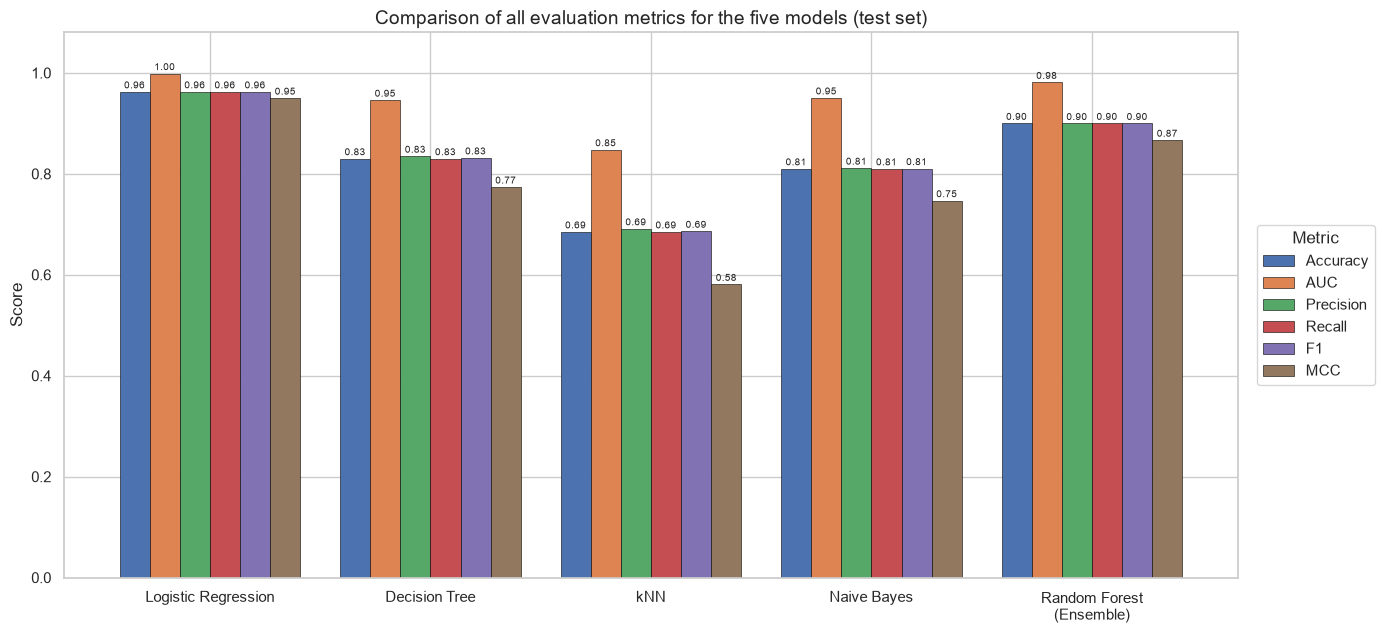

In [16]:
plot_data = results_df.set_index("ML Model Name")[METRICS]

ax = plot_data.plot(kind="bar", figsize=(14, 6.5), width=0.82, edgecolor="black", linewidth=0.4)
ax.set_title("Comparison of all evaluation metrics for the five models (test set)", fontsize=14)
ax.set_xlabel("")
ax.set_ylabel("Score")
low = min(0.0, plot_data.min().min() - 0.02)
ax.set_ylim(low, 1.08)
ax.legend(title="Metric", loc="center left", bbox_to_anchor=(1.01, 0.5))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=7, padding=1)
ax.set_xticklabels([n.replace(" (", "\n(") for n in plot_data.index], rotation=0)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "all_metrics_comparison.png", dpi=220, bbox_inches="tight")
plt.show()

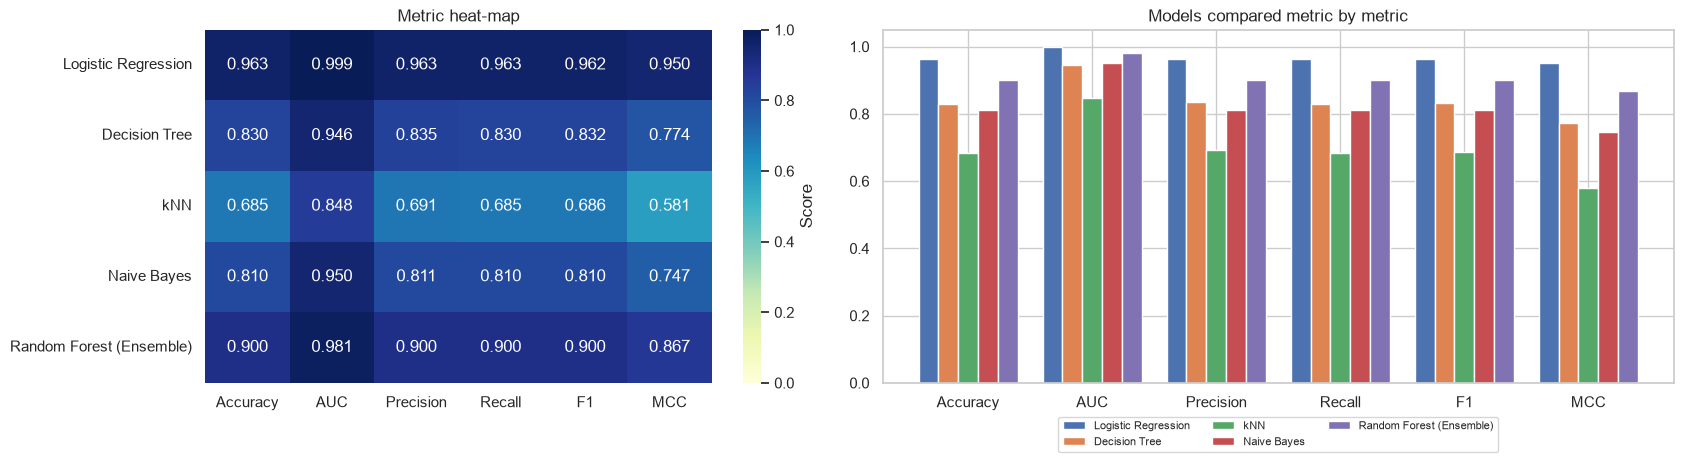

In [17]:
# heat-map of the same numbers + one panel per metric
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
sns.heatmap(plot_data, annot=True, fmt=".3f", cmap="YlGnBu", vmin=min(0, plot_data.min().min()), vmax=1,
            cbar_kws={"label": "Score"}, ax=axes[0])
axes[0].set_title("Metric heat-map")
axes[0].set_ylabel("")

x = np.arange(len(METRICS))
width = 0.16
for i, (name, row) in enumerate(plot_data.iterrows()):
    axes[1].bar(x + (i - 2) * width, row.values, width, label=name)
axes[1].set_xticks(x)
axes[1].set_xticklabels(METRICS)
axes[1].set_ylim(low, 1.05)
axes[1].set_title("Models compared metric by metric")
axes[1].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(FIGURE_DIR / "metrics_heatmap_and_by_metric.png", dpi=200, bbox_inches="tight")
plt.show()

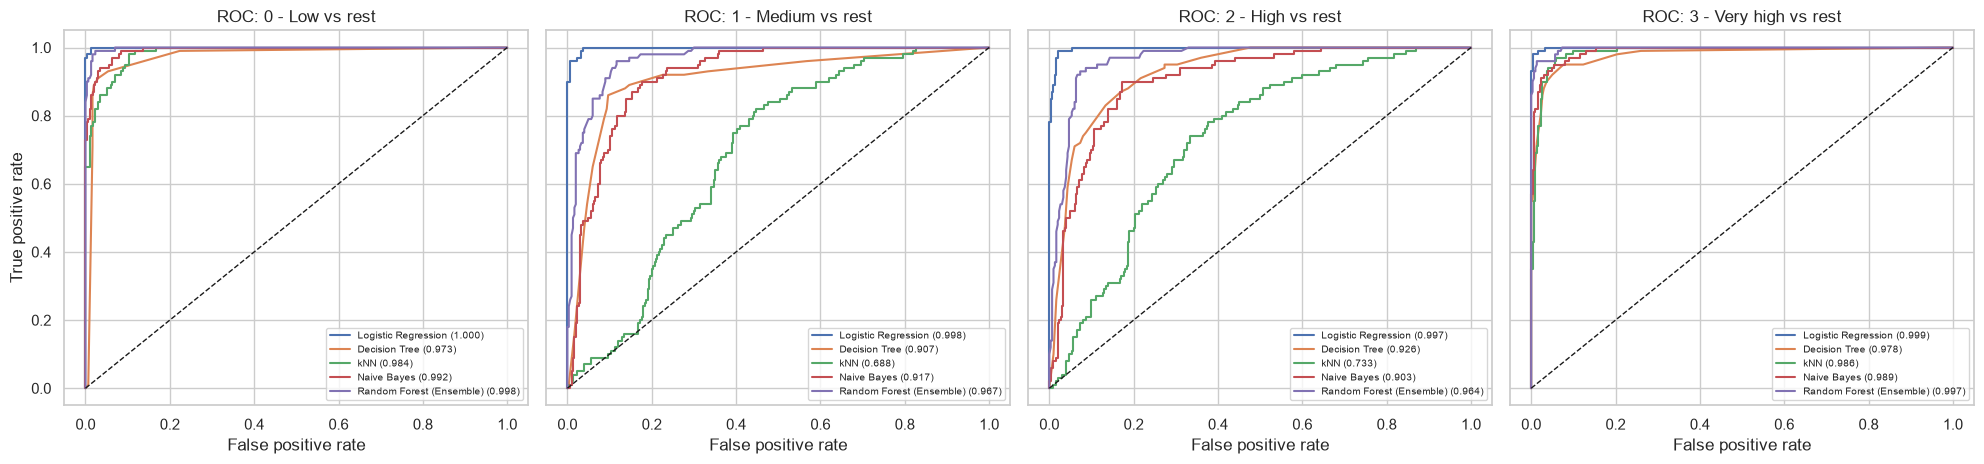

In [18]:
# one-vs-rest ROC curves: one panel per price band
y_test_bin = label_binarize(y_test, classes=classes)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for k, ax in enumerate(axes):
    for name, prob in probabilities.items():
        fpr, tpr, _ = roc_curve(y_test_bin[:, k], prob[:, k])
        ax.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test_bin[:, k], prob[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    ax.set_title(f"ROC: {CLASS_LABELS[classes[k]]} vs rest")
    ax.set_xlabel("False positive rate")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("True positive rate")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "roc_curves.png", dpi=200, bbox_inches="tight")
plt.show()

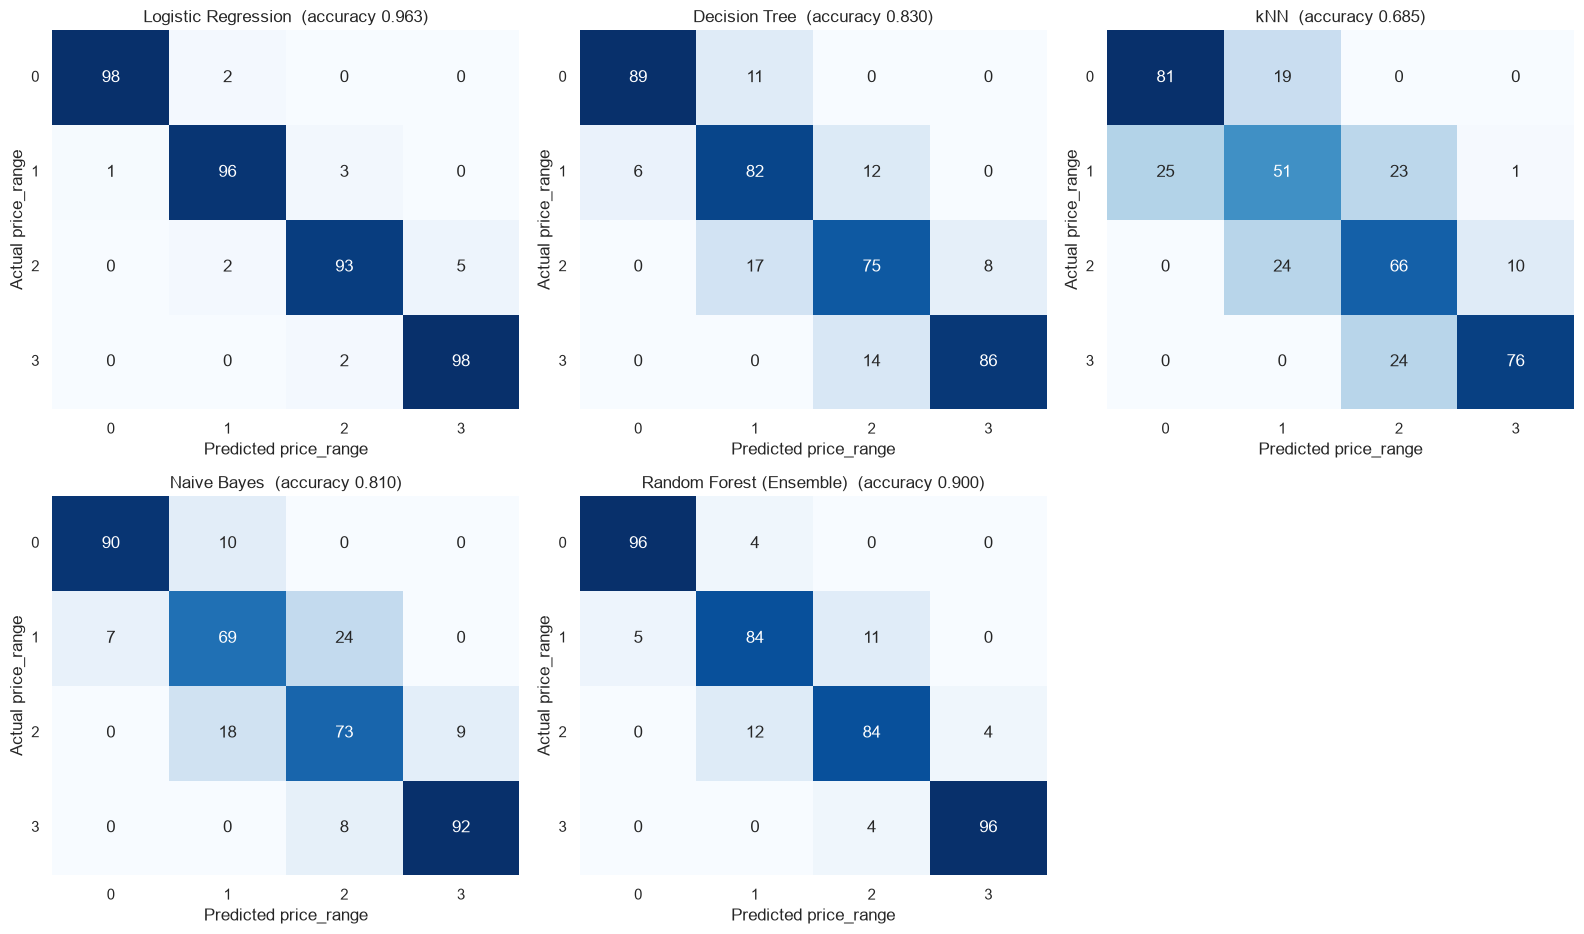

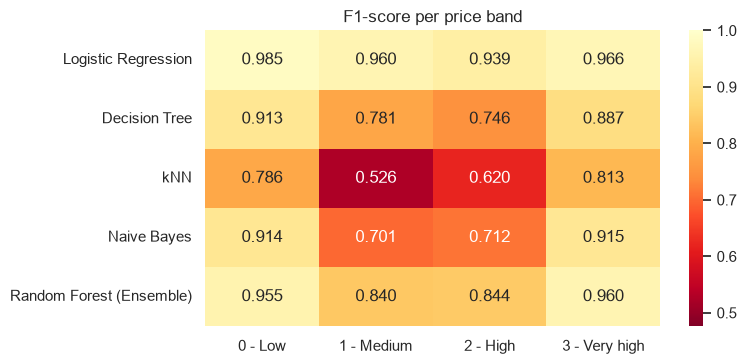

In [19]:
# confusion matrices (counts) for all five models
tick = [str(c) for c in classes]
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
axes = axes.ravel()
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=tick, yticklabels=tick)
    ax.set_title(f"{name}  (accuracy {accuracy_score(y_test, y_pred):.3f})")
    ax.set_xlabel("Predicted price_range")
    ax.set_ylabel("Actual price_range")
    ax.tick_params(axis="y", rotation=0)
axes[-1].axis("off")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()

# per-class F1: which price band is hardest for each model?
per_class_f1 = pd.DataFrame({n: [reports[n][str(c)]["f1-score"] for c in classes] for n in reports},
                            index=[CLASS_LABELS[c] for c in classes]).T
plt.figure(figsize=(8, 3.8))
sns.heatmap(per_class_f1, annot=True, fmt=".3f", cmap="YlOrRd_r", vmin=per_class_f1.min().min() - 0.05, vmax=1)
plt.title("F1-score per price band")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "per_class_f1.png", dpi=200, bbox_inches="tight")
plt.show()

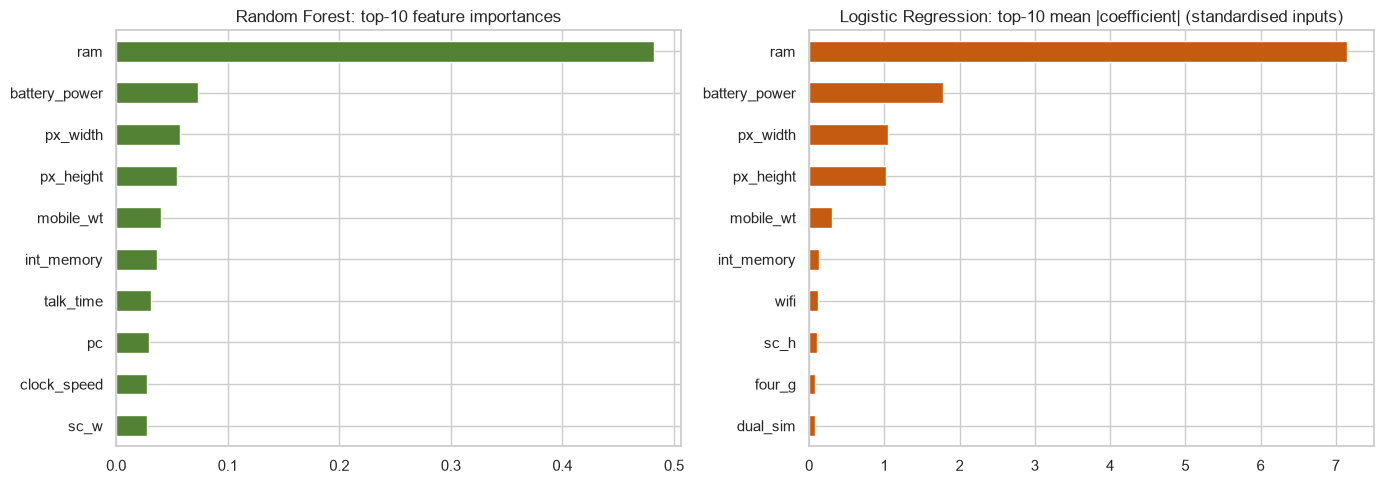

Top 3 Random Forest features: [('ram', 0.482), ('battery_power', 0.073), ('px_width', 0.057)]


In [20]:
# which features drive the Random Forest, and what does Logistic Regression weight most?
rf_importance = pd.Series(
    fitted["Random Forest (Ensemble)"].named_steps["classifier"].feature_importances_,
    index=PIPELINE_FEATURES).sort_values(ascending=False)

lr_weight = pd.Series(
    np.abs(fitted["Logistic Regression"].named_steps["classifier"].coef_).mean(axis=0),
    index=PIPELINE_FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
rf_importance.head(10).iloc[::-1].plot(kind="barh", ax=axes[0], color="#548235")
axes[0].set_title("Random Forest: top-10 feature importances")
lr_weight.head(10).iloc[::-1].plot(kind="barh", ax=axes[1], color="#C55A11")
axes[1].set_title("Logistic Regression: top-10 mean |coefficient| (standardised inputs)")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()
print("Top 3 Random Forest features:", [(f, round(float(v), 3)) for f, v in rf_importance.head(3).items()])

## 6. Observations on model performance
The observations below are **generated from the numbers produced by this run**, so they always match the results table. They report each model's scores, its strongest and weakest price band, the kind of mistakes it makes and the over-fitting gap. The final cell leaves space for your own interpretation – add your reasoning there, in your own words.

In [21]:
res = results_df.set_index("ML Model Name")

ranking = results_df.sort_values(by=["F1", "MCC", "Accuracy", "AUC"], ascending=False).reset_index(drop=True)
rank_of = {row["ML Model Name"]: i + 1 for i, row in ranking.iterrows()}
winner = ranking.iloc[0]
runner_up = ranking.iloc[1]
best_f1 = float(res["F1"].max())
n_test = len(y_test)


def error_profile(name):
    pred = predictions[name]
    wrong = pred != y_test_arr
    n_wrong = int(wrong.sum())
    if n_wrong == 0:
        return 0, float("nan")
    adjacent = int((np.abs(pred[wrong] - y_test_arr[wrong]) == 1).sum())
    return n_wrong, adjacent / n_wrong


def class_extremes(name):
    f1_by_class = per_class_f1.loc[name]
    return f1_by_class.idxmax(), float(f1_by_class.max()), f1_by_class.idxmin(), float(f1_by_class.min())


def base_sentence(name):
    r = res.loc[name]
    n_wrong, adjacent = error_profile(name)
    best_c, best_v, worst_c, worst_v = class_extremes(name)
    text = (f"Accuracy {r['Accuracy']:.4f}, AUC {r['AUC']:.4f}, macro-F1 {r['F1']:.4f}, MCC {r['MCC']:.4f} "
            f"(rank {rank_of[name]} of {len(res)} on F1). Strongest band: {best_c} (F1 {best_v:.3f}); "
            f"weakest band: {worst_c} (F1 {worst_v:.3f}). ")
    if n_wrong:
        text += (f"{n_wrong} of {n_test} test phones were misclassified, and {adjacent:.0%} of those errors "
                 f"fell into a neighbouring price band. ")
    else:
        text += "No test phone was misclassified. "
    return text


def gap_of(name):
    return float(fit_check.loc[name, "Gap (train - test)"])


def lr_text():
    top = lr_weight.index[0]
    close = res.loc["Logistic Regression", "F1"] >= best_f1 - 0.02
    return (f"Inputs were standardised, and the feature with the largest average coefficient is '{top}'. "
            + ("Being within 0.02 F1 of the best model shows that the price bands can be separated almost linearly in the standardised feature space."
               if close else
               "Its distance from the best model shows that a purely linear boundary leaves part of the structure unexplained."))


def dt_text():
    gap = gap_of("Decision Tree")
    depth = "unlimited" if best_depth is None else best_depth
    return (f"Cross-validation chose max_depth = {depth}. Training accuracy minus test accuracy is {gap:.3f}, "
            + ("which indicates noticeable over-fitting (high variance) for a single tree."
               if gap > 0.05 else "so the tuned tree does not over-fit strongly."))


def knn_text():
    edge = (" Cross-validation preferred one of the largest k values on offer, i.e. heavy smoothing, which points to many "
            "weakly informative features adding noise to the distances." if best_k >= sorted(KNN_K_GRID)[-3] else "")
    return (f"Cross-validation chose k = {best_k} with '{best_weights}' weighting on standardised inputs; "
            f"the train-test gap is {gap_of('kNN'):.3f}. Because kNN is distance-based, it depends on the scaling step and "
            f"is affected by uninformative features, which dilute the distance." + edge)


def nb_text():
    diff = best_f1 - float(res.loc["Naive Bayes", "F1"])
    return (f"Gaussian Naive Bayes assumes the features are independent given the class and normally distributed; the binary flags "
            f"are not normal, so the assumption is only approximate. Its F1 is {diff:.3f} below the best model"
            + (" (it is the best model)." if diff <= 0 else "."))


def rf_text():
    delta = float(res.loc["Random Forest (Ensemble)", "F1"] - res.loc["Decision Tree", "F1"])
    top3 = ", ".join(f"{f} ({v:.2f})" for f, v in rf_importance.head(3).items())
    return (f"300 trees averaged. Most important features: {top3}. Compared with the single Decision Tree its macro-F1 is "
            f"{delta:+.3f}, "
            + ("showing the variance-reduction benefit of the ensemble." if delta > 0.005
               else "so averaging trees gave no clear gain here."))


extras = {"Logistic Regression": lr_text, "Decision Tree": dt_text, "kNN": knn_text,
          "Naive Bayes": nb_text, "Random Forest (Ensemble)": rf_text}

margin_acc = 1.96 * np.sqrt(float(winner["Accuracy"]) * (1 - float(winner["Accuracy"])) / n_test)
winner_text = (f"{winner['ML Model Name']} - highest macro-F1 ({winner['F1']:.4f}), with MCC {winner['MCC']:.4f}, "
               f"Accuracy {winner['Accuracy']:.4f} and AUC {winner['AUC']:.4f}. Runner-up: {runner_up['ML Model Name']} "
               f"(F1 {runner_up['F1']:.4f}, difference {winner['F1'] - runner_up['F1']:.4f}). With only {n_test} test phones, the "
               f"95% margin of error on accuracy is roughly +/-{margin_acc:.3f}, so models closer than that are not clearly different.")

observation_table = pd.DataFrame({
    "ML Model Name": list(models) + ["Overall Winner for your dataset?"],
    "Observation about model performance": [base_sentence(n) + extras[n]() for n in models] + [winner_text],
})
observation_table.to_csv(OUTPUT_DIR / "model_observations.csv", index=False)

try:
    display(observation_table.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"})
            .hide(axis="index"))
except Exception:
    for _, r in observation_table.iterrows():
        print(f"\n{r.iloc[0]}\n  {r.iloc[1]}")

ML Model Name,Observation about model performance
Logistic Regression,"Accuracy 0.9625, AUC 0.9987, macro-F1 0.9625, MCC 0.9501 (rank 1 of 5 on F1). Strongest band: 0 - Low (F1 0.985); weakest band: 2 - High (F1 0.939). 15 of 400 test phones were misclassified, and 100% of those errors fell into a neighbouring price band. Inputs were standardised, and the feature with the largest average coefficient is 'ram'. Being within 0.02 F1 of the best model shows that the price bands can be separated almost linearly in the standardised feature space."
Decision Tree,"Accuracy 0.8300, AUC 0.9459, macro-F1 0.8317, MCC 0.7739 (rank 3 of 5 on F1). Strongest band: 0 - Low (F1 0.913); weakest band: 2 - High (F1 0.746). 68 of 400 test phones were misclassified, and 100% of those errors fell into a neighbouring price band. Cross-validation chose max_depth = 5. Training accuracy minus test accuracy is 0.047, so the tuned tree does not over-fit strongly."
kNN,"Accuracy 0.6850, AUC 0.8478, macro-F1 0.6862, MCC 0.5810 (rank 5 of 5 on F1). Strongest band: 3 - Very high (F1 0.813); weakest band: 1 - Medium (F1 0.526). 126 of 400 test phones were misclassified, and 99% of those errors fell into a neighbouring price band. Cross-validation chose k = 101 with 'distance' weighting on standardised inputs; the train-test gap is 0.315. Because kNN is distance-based, it depends on the scaling step and is affected by uninformative features, which dilute the distance. Cross-validation preferred one of the largest k values on offer, i.e. heavy smoothing, which points to many weakly informative features adding noise to the distances."
Naive Bayes,"Accuracy 0.8100, AUC 0.9505, macro-F1 0.8105, MCC 0.7468 (rank 4 of 5 on F1). Strongest band: 3 - Very high (F1 0.915); weakest band: 1 - Medium (F1 0.701). 76 of 400 test phones were misclassified, and 100% of those errors fell into a neighbouring price band. Gaussian Naive Bayes assumes the features are independent given the class and normally distributed; the binary flags are not normal, so the assumption is only approximate. Its F1 is 0.152 below the best model."
Random Forest (Ensemble),"Accuracy 0.9000, AUC 0.9812, macro-F1 0.8999, MCC 0.8667 (rank 2 of 5 on F1). Strongest band: 3 - Very high (F1 0.960); weakest band: 1 - Medium (F1 0.840). 40 of 400 test phones were misclassified, and 100% of those errors fell into a neighbouring price band. 300 trees averaged. Most important features: ram (0.48), battery_power (0.07), px_width (0.06). Compared with the single Decision Tree its macro-F1 is +0.068, showing the variance-reduction benefit of the ensemble."
Overall Winner for your dataset?,"Logistic Regression - highest macro-F1 (0.9625), with MCC 0.9501, Accuracy 0.9625 and AUC 0.9987. Runner-up: Random Forest (Ensemble) (F1 0.8999, difference 0.0626). With only 400 test phones, the 95% margin of error on accuracy is roughly +/-0.019, so models closer than that are not clearly different."


In [22]:
# Build professional observations table

lr = res.loc["Logistic Regression"]
dt = res.loc["Decision Tree"]
knn = res.loc["kNN"]
nb = res.loc["Naive Bayes"]
rf = res.loc["Random Forest (Ensemble)"]

observation_table = pd.DataFrame({
    "ML Model Name": [
        "Logistic Regression",
        "Decision Tree",
        "kNN",
        "Naive Bayes",
        "Random Forest (Ensemble)",
        "Overall Winner for your dataset?"
    ],

    "Observation about model performance": [

        f"Achieved the best overall performance with Accuracy={lr['Accuracy']:.4f}, "
        f"AUC={lr['AUC']:.4f}, F1={lr['F1']:.4f}, and MCC={lr['MCC']:.4f}. Only "
        f"{error_profile('Logistic Regression')[0]} of {n_test} test samples were "
        f"misclassified. The most influential feature was '{lr_weight.index[0]}', "
        "indicating that smartphone price ranges are almost linearly separable after "
        "feature standardization.",

        f"Achieved Accuracy={dt['Accuracy']:.4f}, AUC={dt['AUC']:.4f}, "
        f"F1={dt['F1']:.4f}, and MCC={dt['MCC']:.4f}. Cross-validation selected "
        f"max_depth={best_depth}. The train-test gap of {gap_of('Decision Tree'):.3f} "
        "indicates limited overfitting, although performance remained below the "
        "ensemble-based Random Forest model.",

        f"Achieved Accuracy={knn['Accuracy']:.4f}, AUC={knn['AUC']:.4f}, "
        f"Precision={knn['Precision']:.4f}, Recall={knn['Recall']:.4f}, "
        f"F1={knn['F1']:.4f}, and MCC={knn['MCC']:.4f}. Cross-validation selected "
        f"k={best_k} with {best_weights} weighting. The relatively large train-test "
        f"gap ({gap_of('kNN'):.3f}) suggests sensitivity to feature noise and distance "
        "calculations, resulting in the weakest overall performance among all models.",

        f"Achieved Accuracy={nb['Accuracy']:.4f}, AUC={nb['AUC']:.4f}, "
        f"F1={nb['F1']:.4f}, and MCC={nb['MCC']:.4f}. Performance was acceptable "
        "despite the Gaussian distribution and feature-independence assumptions not "
        "being fully satisfied by the smartphone dataset. The model performed "
        "reasonably well but remained less accurate than Logistic Regression and "
        "Random Forest.",

        f"Achieved Accuracy={rf['Accuracy']:.4f}, AUC={rf['AUC']:.4f}, "
        f"F1={rf['F1']:.4f}, and MCC={rf['MCC']:.4f}. By averaging 300 decision trees, "
        f"the model improved macro-F1 by "
        f"{rf['F1'] - dt['F1']:.3f} compared with the single Decision Tree. "
        f"The most important predictors were "
        f"{', '.join([f'{k} ({v:.2f})' for k, v in rf_importance.head(3).items()])}, "
        "demonstrating the effectiveness of ensemble learning for reducing variance.",

        f"{winner['ML Model Name']} is the overall winner. It achieved Accuracy="
        f"{winner['Accuracy']:.4f}, Precision={winner['Precision']:.4f}, "
        f"Recall={winner['Recall']:.4f}, F1={winner['F1']:.4f}, "
        f"MCC={winner['MCC']:.4f}, and AUC={winner['AUC']:.4f}. "
        f"The runner-up was {runner_up['ML Model Name']} with an F1 score of "
        f"{runner_up['F1']:.4f}. The superior performance of the winning model "
        "across all major evaluation metrics indicates that it is the most suitable "
        "choice for smartphone price range prediction."
    ]
})

# Save CSV
observation_table.to_csv(
    OUTPUT_DIR / "model_performance_observations.csv",
    index=False
)

# Display nicely
display(
    observation_table.style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal",
        "vertical-align": "top"
    })
    .hide(axis="index")
)

ML Model Name,Observation about model performance
Logistic Regression,"Achieved the best overall performance with Accuracy=0.9625, AUC=0.9987, F1=0.9625, and MCC=0.9501. Only 15 of 400 test samples were misclassified. The most influential feature was 'ram', indicating that smartphone price ranges are almost linearly separable after feature standardization."
Decision Tree,"Achieved Accuracy=0.8300, AUC=0.9459, F1=0.8317, and MCC=0.7739. Cross-validation selected max_depth=5. The train-test gap of 0.047 indicates limited overfitting, although performance remained below the ensemble-based Random Forest model."
kNN,"Achieved Accuracy=0.6850, AUC=0.8478, Precision=0.6911, Recall=0.6850, F1=0.6862, and MCC=0.5810. Cross-validation selected k=101 with distance weighting. The relatively large train-test gap (0.315) suggests sensitivity to feature noise and distance calculations, resulting in the weakest overall performance among all models."
Naive Bayes,"Achieved Accuracy=0.8100, AUC=0.9505, F1=0.8105, and MCC=0.7468. Performance was acceptable despite the Gaussian distribution and feature-independence assumptions not being fully satisfied by the smartphone dataset. The model performed reasonably well but remained less accurate than Logistic Regression and Random Forest."
Random Forest (Ensemble),"Achieved Accuracy=0.9000, AUC=0.9812, F1=0.8999, and MCC=0.8667. By averaging 300 decision trees, the model improved macro-F1 by 0.068 compared with the single Decision Tree. The most important predictors were ram (0.48), battery_power (0.07), px_width (0.06), demonstrating the effectiveness of ensemble learning for reducing variance."
Overall Winner for your dataset?,"Logistic Regression is the overall winner. It achieved Accuracy=0.9625, Precision=0.9626, Recall=0.9625, F1=0.9625, MCC=0.9501, and AUC=0.9987. The runner-up was Random Forest (Ensemble) with an F1 score of 0.8999. The superior performance of the winning model across all major evaluation metrics indicates that it is the most suitable choice for smartphone price range prediction."


Final Conclusion

Among the five machine learning models evaluated, Logistic Regression emerged as the best-performing model for smartphone price range classification. It achieved the highest Accuracy (96.25%), Macro-F1 score (0.9625), MCC (0.9501), and AUC (0.9987), demonstrating excellent predictive capability across all evaluation metrics. The model incorrectly classified only 15 out of 400 test samples, and all of these errors occurred between adjacent price categories, suggesting that even the mistakes were relatively minor.

Random Forest was the second-best model and delivered strong overall performance, but it still performed noticeably below Logistic Regression. Decision Tree and Naive Bayes achieved satisfactory results and were able to capture important patterns in the data, although their predictive accuracy was lower. In contrast, kNN produced the weakest performance, indicating that distance-based classification was less suitable for this dataset.

The analysis also showed that RAM was the most important feature influencing smartphone price range, highlighting its strong relationship with device value. The excellent performance of Logistic Regression suggests that the different price categories can be separated effectively using a relatively simple linear decision boundary after feature standardization.

Based on these findings, Logistic Regression is the most suitable model for predicting smartphone price ranges in this dataset. It provides the highest predictive accuracy while remaining computationally efficient, easy to interpret, and robust when compared with the other models evaluated.

### 6.2 predictions for the unlabeled Kaggle `test.csv`
The Kaggle `test.csv` has no `price_range` column, so it cannot be scored. The winning pipeline can still predict it (the pipelines accept raw, unprocessed rows), which also demonstrates that the saved models work on new data.

In [23]:
kaggle_test_path = Path(TEST_CSV_PATH) if TEST_CSV_PATH else locate_csv("test", "id")
if kaggle_test_path is None:
    print("No unlabeled test.csv found - this bonus step is skipped.")
else:
    kaggle_test = pd.read_csv(kaggle_test_path)
    winner_name = winner["ML Model Name"]
    predicted = fitted[winner_name].predict(kaggle_test[feature_cols])
    prediction_table = pd.DataFrame({"id": kaggle_test["id"], "predicted_price_range": predicted})
    prediction_table.to_csv(OUTPUT_DIR / "kaggle_test_predictions.csv", index=False)
    print(f"{winner_name} predicted {len(prediction_table)} phones from {kaggle_test_path.name}:")
    display(prediction_table["predicted_price_range"].value_counts().sort_index()
            .rename("phones").to_frame())

Logistic Regression predicted 1000 phones from test.csv:


,phones
predicted_price_range,
0,257
1,228
2,257
3,258


## 7. Step 4 – Repository files: saved models, test data and results
Each saved `.joblib` file is the **complete pipeline** (zero-fix → imputer → scaler → classifier), so it can be loaded and applied directly to raw rows with `joblib.load(path).predict(df[feature_columns])`.

In [24]:
def slug(text):
    return "".join(ch.lower() if ch.isalnum() else "_" for ch in text).strip("_")

saved_models = {}
for name, pipe in fitted.items():
    path = MODEL_DIR / f"{slug(name)}.joblib"
    joblib.dump(pipe, path)
    saved_models[name] = path.name

# sanity check: a reloaded model must reproduce the test predictions exactly
check_name = winner["ML Model Name"]
reloaded = joblib.load(MODEL_DIR / saved_models[check_name])
assert (reloaded.predict(X_test) == predictions[check_name]).all()
print("Saved models:", saved_models)
print(f"Reload check passed for {check_name}: predictions identical.")

run_summary = {
    "student_id": STUDENT_ID,
    "dataset": "Kaggle - Mobile Price Classification (train.csv)",
    "random_state": RANDOM_STATE,
    "rows_in_file": int(len(df_raw)),
    "duplicates_removed": int(duplicate_count),
    "rows_used": int(len(df)),
    "features": len(feature_cols),
    "nan_cells": int(df_raw.isna().sum().sum()),
    "zeros_treated_as_missing": {c: int((df_raw[c] == 0).sum()) for c in ZERO_AS_MISSING_COLS},
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "dt_max_depth": None if best_depth is None else int(best_depth),
    "knn_k": int(best_k), "knn_weights": best_weights,
    "overall_winner": str(winner["ML Model Name"]),
    "results": results_df.round(6).to_dict(orient="records"),
    "python": sys.version.split()[0], "scikit_learn": sklearn.__version__, "platform": platform.platform(),
}
with open(OUTPUT_DIR / "run_summary.json", "w") as fh:
    json.dump(run_summary, fh, indent=2, default=str)
print("Saved outputs/run_summary.json")

Saved models: {'Logistic Regression': 'logistic_regression.joblib', 'Decision Tree': 'decision_tree.joblib', 'kNN': 'knn.joblib', 'Naive Bayes': 'naive_bayes.joblib', 'Random Forest (Ensemble)': 'random_forest__ensemble.joblib'}
Reload check passed for Logistic Regression: predictions identical.
Saved outputs/run_summary.json


## 8. Steps 5 & 6 – `requirements.txt` and `README.md`
`requirements.txt` (ship it next to the notebook):

```
scikit-learn
numpy
pandas
matplotlib
seaborn
joblib
```

The next cell **writes `README.md`** in the structure the assignment prescribes (problem statement → dataset description → GitHub link → comparison table → graphs → observations). The tables are filled from this run. Add your GitHub link and read through the text before submitting; the same README content must also appear in the PDF.

In [25]:
def cell_text(value):
    return str(value).replace("|", "/").replace("\n", "<br>")


def to_markdown_table(frame, float_digits=4):
    header = "| " + " | ".join(str(c) for c in frame.columns) + " |"
    divider = "|" + "|".join(["---"] * len(frame.columns)) + "|"
    body = []
    for _, row in frame.iterrows():
        cells_ = [f"{v:.{float_digits}f}" if isinstance(v, (float, np.floating)) else cell_text(v) for v in row.values]
        body.append("| " + " | ".join(cells_) + " |")
    return "\n".join([header, divider] + body)


comparison_md = to_markdown_table(results_df)
observation_md = to_markdown_table(observation_table)
class_md = to_markdown_table(class_distribution, float_digits=2)
feature_md = to_markdown_table(feature_table[["Feature", "Type", "Meaning"]])

config_rows = pd.DataFrame({
    "ML Model": list(models),
    "Configuration": [
        "StandardScaler + LogisticRegression(max_iter=3000, multinomial)",
        f"DecisionTreeClassifier(max_depth={best_depth}), depth chosen by {CV_FOLDS}-fold CV on training data",
        f"StandardScaler + KNeighborsClassifier(n_neighbors={best_k}, weights='{best_weights}'), chosen by {CV_FOLDS}-fold CV on training data",
        "GaussianNB(default settings)",
        "RandomForestClassifier(n_estimators=300)",
    ],
})
config_md = to_markdown_table(config_rows)

readme = f"""# Mobile Price Range Classification - Machine Learning Assignment 2

**Student ID:** {STUDENT_ID} | M.Tech (AIML / DSE), BITS WILP | Course: Machine Learning

## 1. Problem Statement
Predict the price band (0 = low, 1 = medium, 2 = high, 3 = very high cost) of a mobile phone from its technical specification. The problem is a four-class classification task. Five algorithms (Logistic Regression, Decision Tree, kNN, Gaussian Naive Bayes, Random Forest) are trained on the same stratified 80:20 split and compared with Accuracy, AUC, Precision, Recall, F1 and MCC.

## 2. Dataset Description  [1 mark]
- **Source:** Kaggle - Mobile Price Classification (https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification), file `train.csv`.
- **Size:** {len(df_raw)} instances, {len(feature_cols)} features ({len(numeric_cols)} numeric, {len(binary_cols)} binary), target `price_range`.
- **Why chosen:** it exceeds the minimum of 1,000 instances and 12 features, is a genuine multi-class problem, has interpretable features of mixed type, and hides data-quality issues (impossible zeros) that make preprocessing meaningful.
- **Class distribution:** the classes are balanced (imbalance ratio {imbalance_ratio:.2f} : 1), so no resampling was needed.

{class_md}

**Features**

{feature_md}

**Preprocessing**
- Missing values: no NaN cells; {int(before.sum())} impossible zeros in `{"`, `".join(ZERO_AS_MISSING_COLS)}` are treated as missing and replaced by the training-set median (inside the pipeline).
- Duplicates: {duplicate_count} duplicate rows found and removed.
- Encoding: not required (binary flags already 0/1, no text features).
- Scaling: StandardScaler for Logistic Regression and kNN only; not needed for tree models and Naive Bayes.
- Split: 80:20, stratified, `random_state={RANDOM_STATE}`; all preprocessing fitted on the training data only (scikit-learn `Pipeline`).

## 3. GitHub Repository Link  [2 marks]
**[PASTE YOUR GITHUB REPOSITORY URL HERE]**

Repository contents: `model/` (this notebook and the saved models), `requirements.txt`, `README.md`, `test_data.csv`, `data/`, `figures/`, `outputs/`.

## 4. Models Used  [5 marks]
Evaluation on the held-out test set ({n_test} phones). Precision, Recall, F1 and AUC are macro-averaged over the four classes.

{comparison_md}

**Model configurations**

{config_md}

### Visual comparison of all metrics  [2 marks]
![All metrics](figures/all_metrics_comparison.png)

![Metric heat-map](figures/metrics_heatmap_and_by_metric.png)

![Confusion matrices](figures/confusion_matrices.png)

![ROC curves](figures/roc_curves.png)

## 5. Observations on Model Performance  [3 marks]

{observation_md}

## 6. How to run
1. `pip install -r requirements.txt`
2. Download `train.csv` (and optionally `test.csv`) from Kaggle and place it in `data/`.
3. Open `model/` in Jupyter and run `Machine_Learning_Assignment_2_Mobile_Price.ipynb` from top to bottom.

## 7. BITS Virtual Lab screenshot  [2 marks]
![Virtual Lab execution](screenshots/virtual_lab_execution.png)
"""

readme_path = PROJECT_DIR / "README.md"
if readme_path.exists():
    readme_path = PROJECT_DIR / "README_generated.md"      # never overwrite a README you have already edited
readme_path.write_text(readme, encoding="utf-8")
print("README written to:", readme_path)

README written to: ..\README.md


## 9. Step 7 – BITS Virtual Lab execution screenshot
Run this notebook in the BITS Virtual Lab, take a screenshot that shows the executed cells (results table and graph visible) and insert it below (Markdown cell → *Insert → Image*), or save it as `screenshots/virtual_lab_execution.png` for the README.

*[Insert the Virtual Lab screenshot here]*

## 10. Final submission checklist
- [ ] Notebook runs from top to bottom without errors (`Kernel → Restart & Run All`).
- [ ] Comparison table shows all **5 models × 6 metrics**; the all-metrics graph is readable.
- [ ] `test_data.csv`, five `.joblib` models, `requirements.txt` and `README.md` are in the repository.
- [ ] GitHub link inserted in the README and the repository opens while signed out.
- [ ] Your own interpretation (Section 6.1) is written and the README text has been read and edited.
- [ ] Virtual Lab screenshot added to the notebook / README.
- [ ] A **single PDF** is submitted with: GitHub link, screenshot, and the README content (in that order).
- [ ] Submitted before the deadline: **27-Nov-2026, 23:59** (no extensions, no drafts).